In [1]:
suppressPackageStartupMessages({
    library(Seurat, quietly = T)
    library(ggplot2, quietly = T)
    library(patchwork, quietly = T)
    library(tidyr, quietly = T)

    library(reticulate, quietly = T)
    reticulate::use_condaenv("STAT4_followup", required = TRUE)
    reticulate::py_config()  
    kneed <- reticulate::import("kneed")
})

In [2]:
data_path = '/data3/hratch/STAT4_followup'

# Load and Subset Data

In [3]:
nk.integrated<-readRDS(file = 
                         file.path(data_path, 'processed', 'pbmc_integrated.RDS')
                        ) 
# downloaded directly from Zenodo https://zenodo.org/records/7713994


In [4]:
nk.cells <- subset(nk.integrated, subset = Cell.Type == "Natural killer  cells")
nk.cells

An object of class Seurat 
21621 features across 550 samples within 2 assays 
Active assay: integrated (2000 features, 2000 variable features)
 2 layers present: data, scale.data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

# Reprocess

We need to define the variability within the NK subset

In [5]:
DefaultAssay(nk.cells) <- "RNA"
nk.cells <- CreateSeuratObject(
  counts    = LayerData(nk.cells, assay = "RNA", layer = "counts"),
  meta.data = nk.cells@meta.data[, c("orig.ident", "nCount_RNA", "nFeature_RNA", "percent.mt")]
)
Idents(nk.cells) <- "orig.ident"

# Reciprocal PCA

**This is a key decision point -- could not batch correct to preserve as much variability as possible, since "batch" and "disease state" are confounded (1 sample per disease state). We will proceed with batch correction for now as it is more conservative, and see if we are still capturing the biological differences of interest**. Particularly since Seurat says this is moer conservative than CCA. 

In [6]:
nk.list <- SplitObject(nk.cells, split.by = "orig.ident")
sapply(nk.list, ncol)

Control Patient.2 Patient.1 
      177       152       221

Repeat as in 01B_Transform notebook

In [7]:
suppressMessages({
    suppressWarnings({
        nk.list <- lapply(X = nk.list, FUN = function(x){
            x <- NormalizeData(x, normalization.method = "LogNormalize", scale.factor = 1e6)
            x <- FindVariableFeatures(x, selection.method = "vst", nfeatures = 2000)
        })
    })
})


In [8]:
features <- SelectIntegrationFeatures(object.list = nk.list)

# creates unecessary warning of # of PCs
nk.list <- lapply(X = nk.list, FUN = function(x) {
    x <- ScaleData(x, features = features, verbose = FALSE)
    x <- suppressWarnings(RunPCA(x, npcs = 100, features = features, verbose = FALSE)) # 100 PCs instead of 50 as originally done
})


A difference here is  the number of PCs is using kneed automated elbow selection.

Control: 8 PCs
 Patient.2: 10 PCs
 Patient.1: 8 PCs


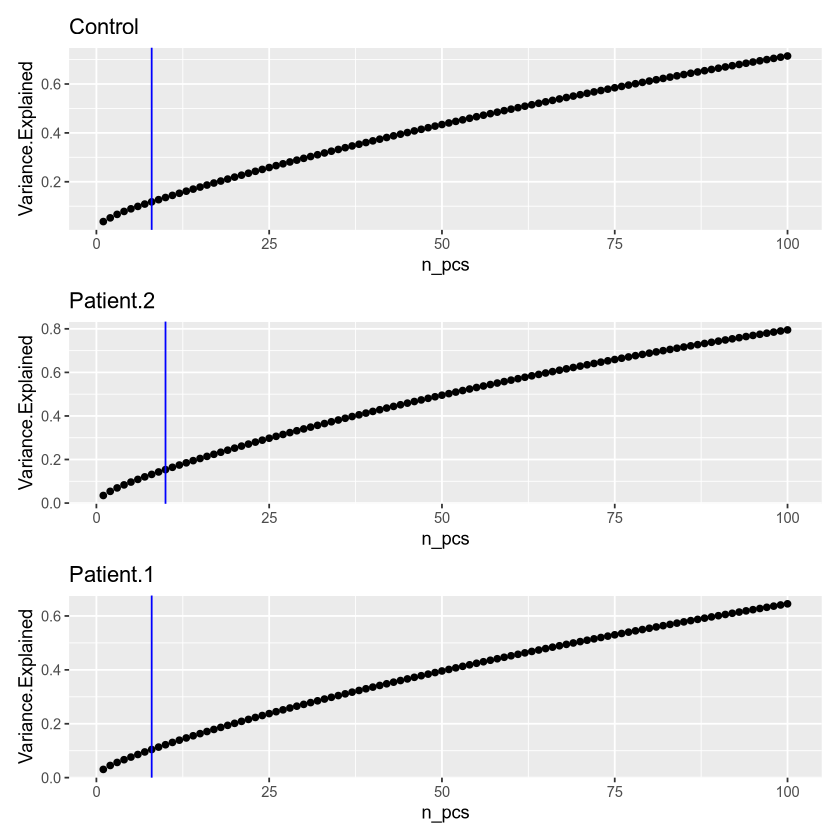

In [9]:
pca.var <- function(so) {
  eig_values <- so[["pca"]]@stdev^2
  pcs <- seq_along(eig_values)

  knee <- kneed$KneeLocator(
    pcs, eig_values,
    S = 1,
    curve = "convex",
    direction = "decreasing"
  )

  n_pcs <- knee$knee
  if (is.null(n_pcs)) stop("No PCA elbow detected.")
  n_pcs <- as.integer(n_pcs)

  total_variance <- sum(matrixStats::rowVars(so[["RNA"]]$scale.data))
  viz_df <- data.frame(
    n_pcs = pcs,
    Variance.Explained = cumsum(eig_values / total_variance)
  )

  g <- ggplot(viz_df, aes(n_pcs, Variance.Explained)) +
    geom_point() +
    geom_vline(xintercept = n_pcs, color = "blue")

  list(n_pcs = n_pcs, plot = g)
}

results <- lapply(nk.list, pca.var)
selected_pcs <- vapply(results, function(x) x$n_pcs, integer(1))

g3 <- wrap_plots(
  lapply(names(results), function(name) results[[name]]$plot + ggtitle(name)),
  ncol = 1
)

cat(sprintf("%s: %d PCs\n", names(selected_pcs), selected_pcs))
g3

In [134]:
# n_pcs = max(selected_pcs) # this is new, rather than using the default
n_pcs = 30 # adding some leeway since integrating and there is a continual linear increase for all of them
# while still reducing dimensionality from the few cells per sample; and this is the default

k.anchor = 7 #6 #5 #8 #7, 10, 20,

# k of 5 gives a blend of control/vsnot and sample-specific clusters
# k of 8 already has everything mixes

suppressMessages({
    nk.anchors <- FindIntegrationAnchors(
        object.list = nk.list, anchor.features = features, 
        scale = F, # since already scaled above, according to documentation
        normalization.method = 'LogNormalize', 
         reduction = "rpca", 
        dims = 1:n_pcs, 
        k.anchor = k.anchor #make stronger because downstream clusters split by sample with default of 5
        )
    nk.integrated <- IntegrateData(
        anchorset = nk.anchors, normalization.method = 'LogNormalize', 
        k.weight = 30 # too many by default
        )
})


Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Different cells in new layer data than already exists for scale.data”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”


In [135]:
# specify that we will perform downstream analysis on the corrected data note that the
# original unmodified data still resides in the 'RNA' assay
DefaultAssay(nk.integrated) <- "integrated"

# Dimensionality Reduction and Clustering

In [136]:
# Run the standard workflow for visualization and clustering
nk.integrated <- ScaleData(nk.integrated, verbose = FALSE)
nk.integrated <- RunPCA(nk.integrated, npcs = 100, verbose = FALSE)

Integrated NK cells: 10 PCs


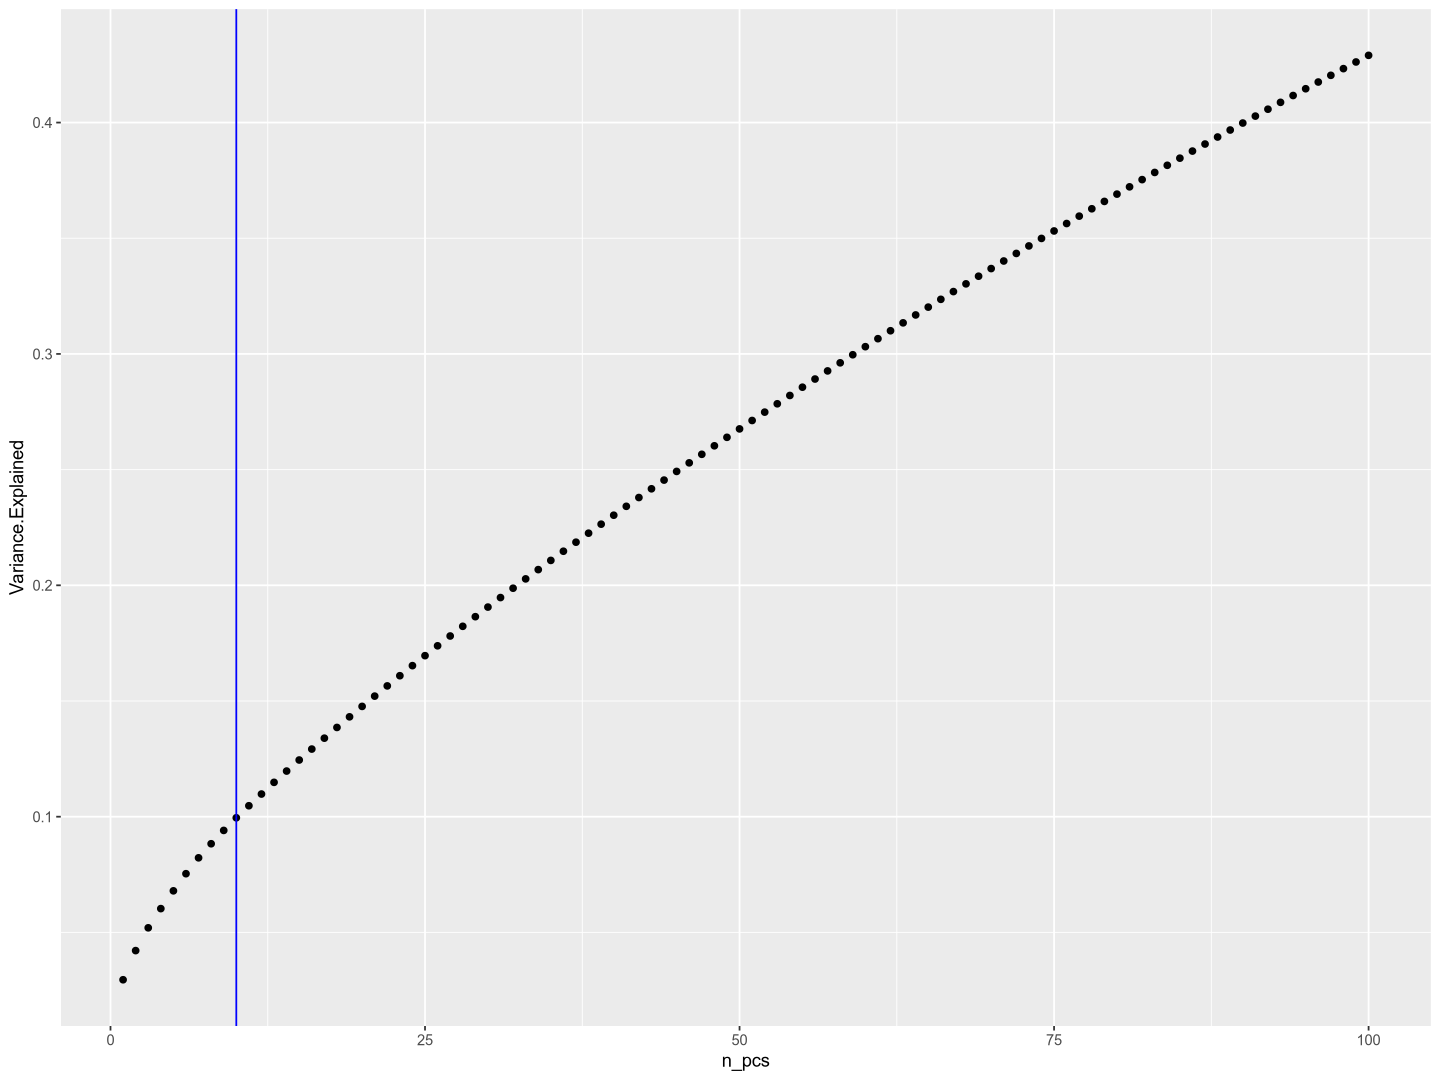

In [137]:
pca.var <- function(so) {
  eig_values <- so[["pca"]]@stdev^2
  pcs <- seq_along(eig_values)

  knee <- kneed$KneeLocator(
    pcs, eig_values,
    S = 1,
    curve = "convex",
    direction = "decreasing"
  )

  n_pcs <- knee$knee
  if (is.null(n_pcs)) stop("No PCA elbow detected.")
  n_pcs <- as.integer(n_pcs)

  total_variance <- sum(matrixStats::rowVars(so[["integrated"]]$scale.data))
  viz_df <- data.frame(
    n_pcs = pcs,
    Variance.Explained = cumsum(eig_values / total_variance)
  )

  g <- ggplot(viz_df, aes(n_pcs, Variance.Explained)) +
    geom_point() +
    geom_vline(xintercept = n_pcs, color = "blue")

  list(n_pcs = n_pcs, plot = g)
}

result <- pca.var(nk.integrated)
n_pcs <- result$n_pcs
cat(sprintf("Integrated NK cells: %d PCs\n", n_pcs))
result$plot

In [138]:
suppressWarnings({
    suppressMessages({
        nk.integrated <- RunUMAP(nk.integrated, reduction = "pca", dims = 1:n_pcs)
        nk.integrated <- FindNeighbors(nk.integrated, reduction = "pca", dims = 1:n_pcs)
    })
})

## Cluster Selection

We'll do a sweep of resolution parameters because this will be important for identifying subclusters:

In [139]:
resolutions <- seq(0.1, 2.0, by = 0.1)
# resolutions<-c(0.01, 0.05, resolutions)
nk.integrated <- FindClusters(
  nk.integrated,
  graph.name = "integrated_snn",
  resolution = resolutions,
  verbose = FALSE
)

# for (res in resolutions) {
#   cat(sprintf("Clustering at resolution %.1f ... ", res))
#   flush.console()

#   nk.integrated <- FindClusters(
#     nk.integrated,
#     graph.name = "integrated_snn",
#     resolution = res,
#     verbose = FALSE
#   )

#   cat("done\n")
# }

# Compare cluster count, smallest cluster, and PCA-space silhouette
pc_dist <- dist(
  Embeddings(nk.integrated[["pca"]])[, 1:n_pcs, drop = FALSE]
)

scores <- t(vapply(resolutions, function(res) {
  col <- paste0("integrated_snn_res.", res)
  clusters <- as.integer(factor(nk.integrated@meta.data[[col]]))
  sizes <- tabulate(clusters)
  n_clusters <- length(sizes)

  c(
    n_clusters = n_clusters,
    smallest_cluster = min(sizes),
    mean_silhouette = if (n_clusters >= 2 &&
                          n_clusters < length(clusters)) {
      mean(cluster::silhouette(clusters, pc_dist)[, "sil_width"])
    } else {
      NA_real_
    }
  )
}, numeric(3)))

resolution_summary <- data.frame(
  resolution = resolutions,
  scores,
  row.names = NULL
)


In [140]:
# resolution_summary

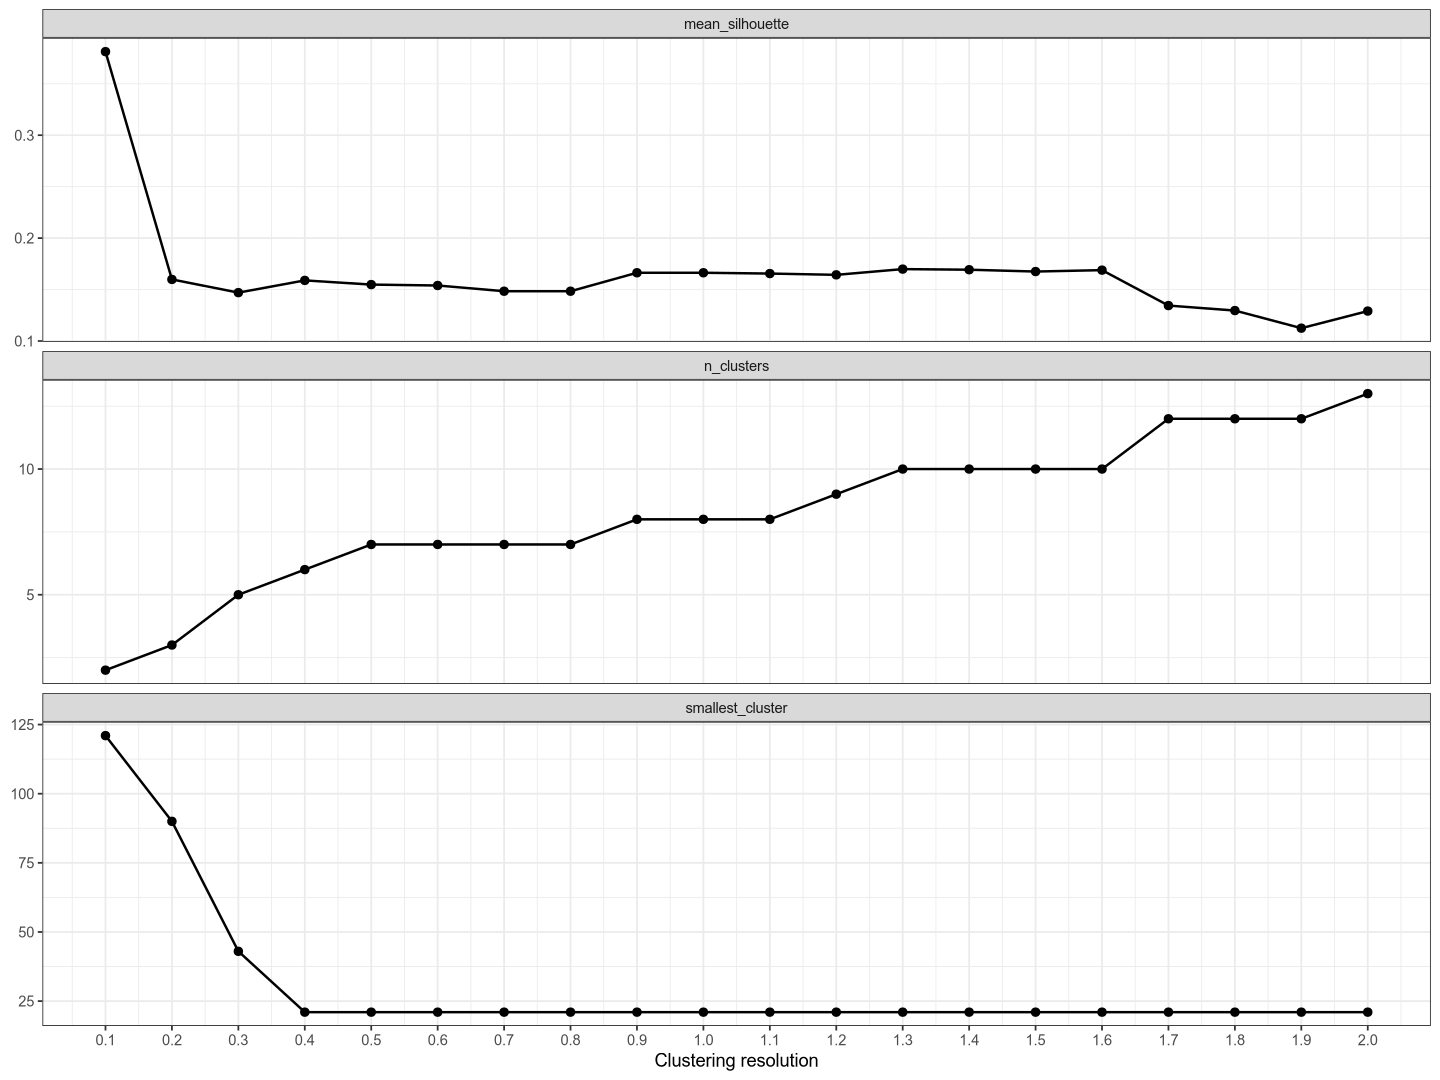

In [141]:
plot_df <- tidyr::pivot_longer(
  resolution_summary,
  cols = -resolution,
  names_to = "metric",
  values_to = "value"
)

ggplot(plot_df, aes(x = resolution, y = value)) +
  geom_line(linewidth = 0.7) +
  geom_point(size = 2) +
  facet_wrap(~ metric, scales = "free_y", ncol = 1) +
  scale_x_continuous(breaks = resolution_summary$resolution) +
  labs(x = "Clustering resolution", y = NULL) +
  theme_bw()

In [167]:
resolution<-0.3

nk.integrated <- FindClusters(
  nk.integrated,
  graph.name = "integrated_snn",
  resolution = resolution,
  verbose = FALSE
)

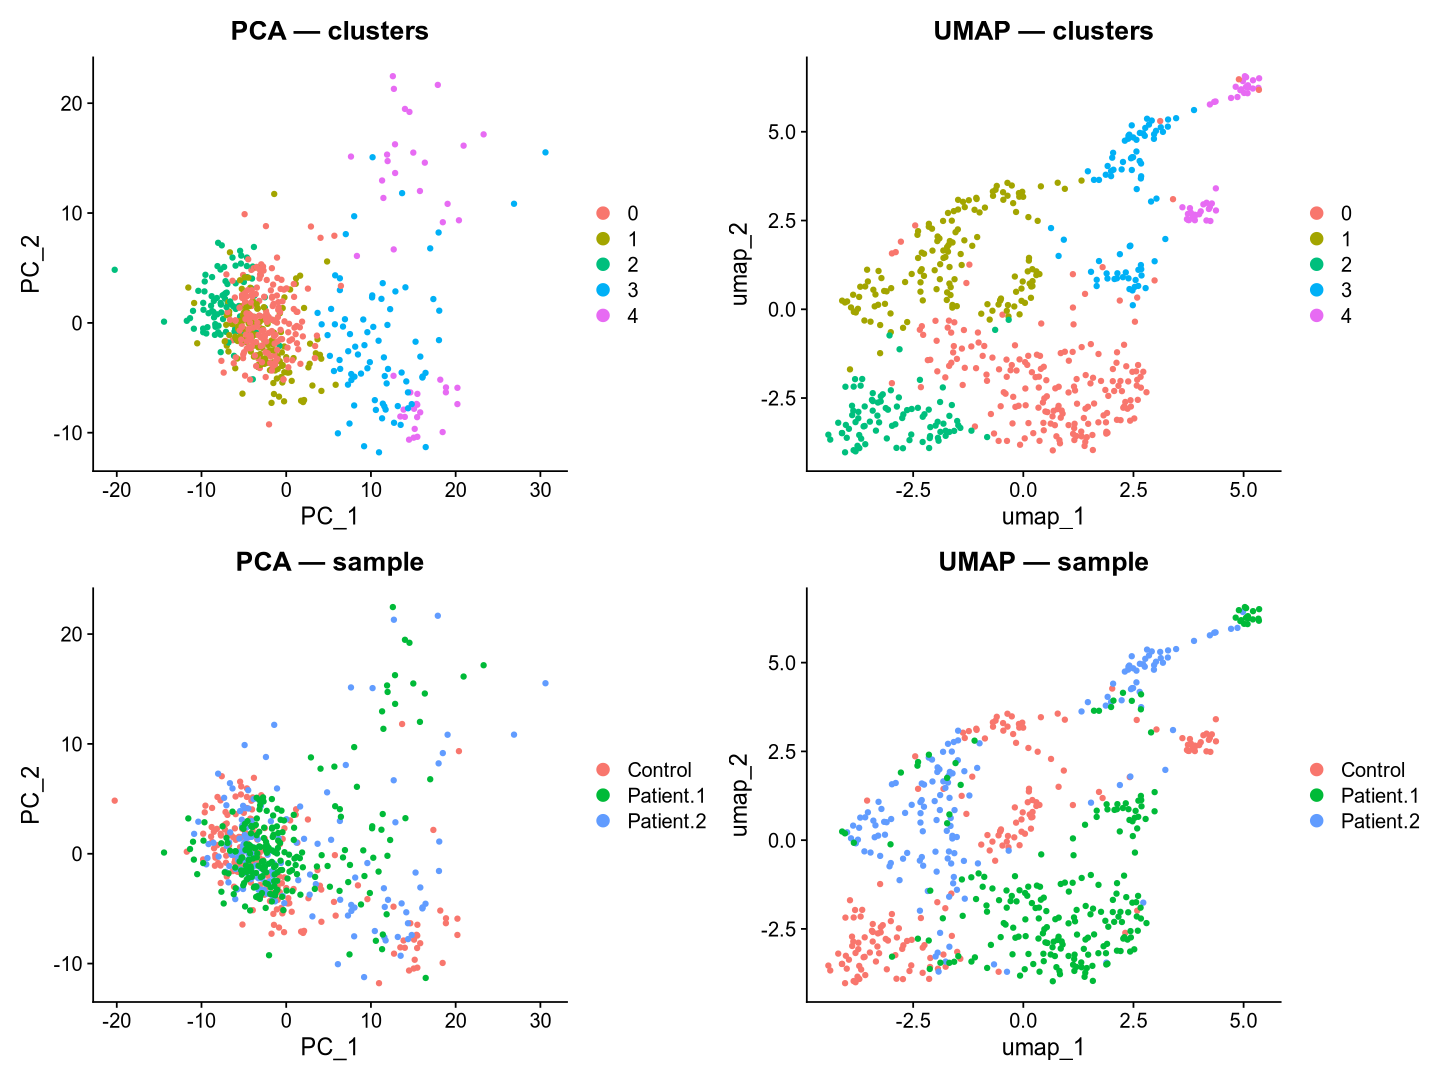

In [168]:
options(repr.plot.width = 12, repr.plot.height = 9)

plots <- list(
  DimPlot(nk.integrated, reduction = "pca",
          group.by = "seurat_clusters") + ggtitle("PCA — clusters"),
  DimPlot(nk.integrated, reduction = "umap",
          group.by = "seurat_clusters") + ggtitle("UMAP — clusters"),
  DimPlot(nk.integrated, reduction = "pca",
          group.by = "orig.ident") + ggtitle("PCA — sample"),
  DimPlot(nk.integrated, reduction = "umap",
          group.by = "orig.ident") + ggtitle("UMAP — sample")
)

patchwork::wrap_plots(plots, ncol = 2)


<span style="color: red;">For Lori: We can tune the following two parameters: (1) The extent to which subclusters are sample-specific vs mixed. (2) The number of subclusters. I found that this gave a balance of mixing in a way that we may be interested in the biology.</span>

The benefit of clustering is it can show the extent to which clusters are separated vs continuous, and it can group cells from different samples with similar phenotypes while showing which sample has a relatively larger proportion of cells in a given cluster/phenotype. 

This table shows the relative frequency of cells in a given cluster derived from a given sample:

In [176]:
counts <- as.data.frame.matrix(
  table(
    nk.integrated$seurat_clusters,
    nk.integrated$orig.ident
  )
)

counts <- counts[, c("Control", "Patient.1", "Patient.2")]
colnames(counts) <- c("Control", "Patient 1 - On treatment", "Patient 2 - Off Treatment")

round(counts / rowSums(counts), 3)

,Control,Patient 1 - On treatment,Patient 2 - Off Treatment
,<dbl>,<dbl>,<dbl>
0,0.068,0.795,0.137
1,0.432,0.088,0.480
2,0.769,0.121,0.110
3,0.103,0.397,0.500
4,0.512,0.349,0.140


We can compare this to the relative frequency of cells derived from a given sample across all NK cells independent of cluster:

In [174]:
counts <- sapply(nk.list, ncol)
fractions <- (counts / sum(counts))[c("Control", "Patient.1", "Patient.2")]

names(fractions) <- c("Control", "Patient 1 - On treatment", "Patient 2 - Off Treatment")
cat(sprintf("%s: %.3f", names(fractions), fractions), sep = "\n")

Control: 0.322
Patient 1 - On treatment: 0.402
Patient 2 - Off Treatment: 0.276


Table relative to overall population frequency (negative means depleted, positive means enriched):

In [178]:
proportions <- counts / rowSums(counts)

round(
  sweep(proportions, 2, fractions[colnames(proportions)], FUN = "-"),
  3
)

,Control,Patient 1 - On treatment,Patient 2 - Off Treatment
,<dbl>,<dbl>,<dbl>
0,-0.253,0.393,-0.140
1,0.111,-0.314,0.203
2,0.447,-0.281,-0.166
3,-0.219,-0.004,0.224
4,0.190,-0.053,-0.137


From this we can see that:
- Cluster 0 is Patient 1 specific
- Cluster 1 is Control and Patient 2
- Cluster 2 is Control specific
- Cluster 3 maintains the same frequency for Patient 1, but is enriched for Patient 2
- Cluster 4 is somewhat control specific, while maintaining a substantial amount of Patient 1.

Patient 1 is on-treatment, Patien 2 is off-treatment. Cluster 3-4 are the most relevant grouping. Cluster 3 is closest to a off-treatment specific cluster, though still a lot of on-treatment patient cells (which could make sense, these could still be the disease phenotype).  Cluster 0 is a bit counterintuitive for separating the Patient on treatment away from both the off-treatment and control. Cluster 1 is similarly counterintuitive for grouping the control with the off treatment patient. 

- Clusters 2 (control-specific) and 3 are complementary 
- Clusters 0 (on-treatment Patient 1 specific) and 1 (control and off-treatment Patient 2) are commplementary

In [182]:
Checkpoint:

ERROR: Error in parse(text = input): <text>:2:0: unexpected end of input
1: Checkpoint:
   ^


In [ ]:
saveRDS(nk.integrated, file.path(data_path, 'processed', 'nk_subclusters.rds'))

# Markers

Here, we ask what distinguishes each cluster from the rest. We find markers as in notebooks 01C (DEPR: except we include downregulated genes to see overall program differences).

In [231]:
nk.integrated<-readRDS(file.path(data_path, 'processed', 'nk_subclusters.rds'))
nk.de <- JoinLayers(nk.integrated, assay = "RNA")

In [232]:
markers.wilcoxon<-FindAllMarkers(
    object = nk.de, 
    assay = 'RNA', only.pos = F, # DEPR include negative to see downregulated
    slot = 'data', test.use = 'wilcox', 
    min.pct = 0.25, # stringent since markers
    logfc.threshold = 0.5
    )
write.csv(markers.wilcoxon, file.path(data_path, 'processed', "NK_subcluster_markers.csv"))

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4



In [223]:
markers.wilcoxon <- read.csv(
    file.path(data_path, "processed", "NK_subcluster_markers.csv"),
    row.names = 1
)
markers.wilcoxon$cluster <- factor(
    markers.wilcoxon$cluster,
    levels = levels(nk.de$seurat_clusters)
)

In [230]:
# pval_thresh = 0.05
# lfc_thresh = 1.5

# markers<-markers.wilcoxon[markers.wilcoxon$p_val_adj <= pval_thresh,] 
# markers <- markers[abs(markers$avg_log2FC) > lfc_thresh, ]
# table(markers$cluster)

Filter for significance:

In [233]:
pval_thresh = 0.05
lfc_thresh = 1.5

markers<-markers.wilcoxon[markers.wilcoxon$p_val_adj <= pval_thresh,] 
markers <- markers[abs(markers$avg_log2FC) > lfc_thresh, ]
table(markers$cluster)


 0  1  2  3  4 
11  0 11 57 66 

In [237]:
cluster_sheets <- split(markers, markers$cluster, drop = FALSE)

cluster_sheets <- lapply(cluster_sheets, function(df) {
    df[order(abs(df$avg_log2FC), decreasing = TRUE), , drop = FALSE]
})

names(cluster_sheets) <- paste0("Cluster_", names(cluster_sheets))

openxlsx::write.xlsx(
    cluster_sheets,
    file = file.path(data_path, "processed", "NK_subcluster_sig_markers.xlsx"),
    rowNames = FALSE,
    overwrite = TRUE
)